# Day 5 · numpy 进阶 + matplotlib

**上午**：axis 参数、聚合、拼接、np.linalg
**下午**：matplotlib 画图
**晚上**：余弦相似度综合练习

## 1. axis 是本周最大的坑

In [4]:
import numpy as np

a = np.arange(12).reshape(3,4)
print(a.sum())        # 全部元素之和
print(a.sum(axis=0))  # 沿行方向压扁 -> 每列的和
print(a.sum(axis=1))  # 沿列方向压扁 -> 每行的和
print(a.mean(axis=1, keepdims=True).shape)  # keepdims 为什么重要？（想想广播）keepdims=True 让你的聚合结果保留“维度信息”，从而能直接和原数组广播

66
[12 15 18 21]
[ 6 22 38]
(3, 1)


## 2. 拼接与线性代数

In [5]:
a = np.ones((2,3)); b = np.zeros((2,3))
print(np.concatenate([a,b], axis=0).shape, np.concatenate([a,b], axis=1).shape)
A = np.random.rand(3,3)
print(np.linalg.det(A))
print(np.linalg.inv(A) @ A)  # 应接近单位矩阵

(4, 3) (2, 6)
-0.02570945591941794
[[ 1.00000000e+00 -3.16795010e-15 -2.83522465e-16]
 [-8.60644702e-16  1.00000000e+00  6.07421719e-17]
 [ 5.28730019e-16  1.16838271e-15  1.00000000e+00]]


## 3. matplotlib 基础

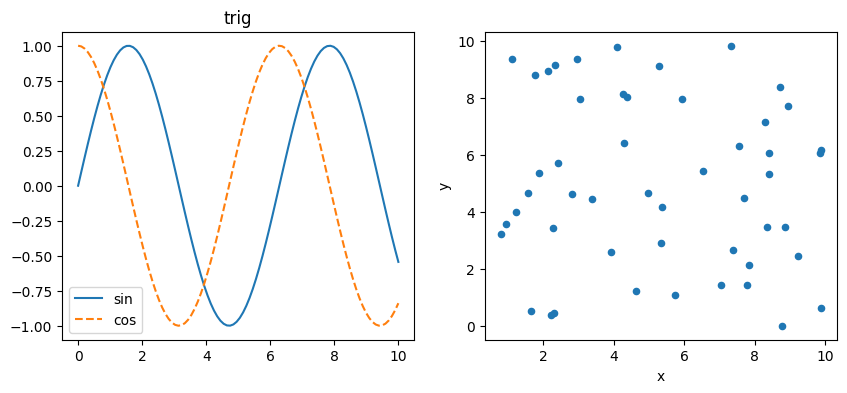

In [6]:
import matplotlib.pyplot as plt
x = np.linspace(0, 10, 100)
fig, axes = plt.subplots(1, 2, figsize=(10,4))
axes[0].plot(x, np.sin(x), label='sin')
axes[0].plot(x, np.cos(x), '--', label='cos')
axes[0].legend(); axes[0].set_title('trig')
axes[1].scatter(np.random.rand(50)*10, np.random.rand(50)*10, s=20)
axes[1].set_xlabel('x'); axes[1].set_ylabel('y')
plt.show()

## 4. 练习：随机游走

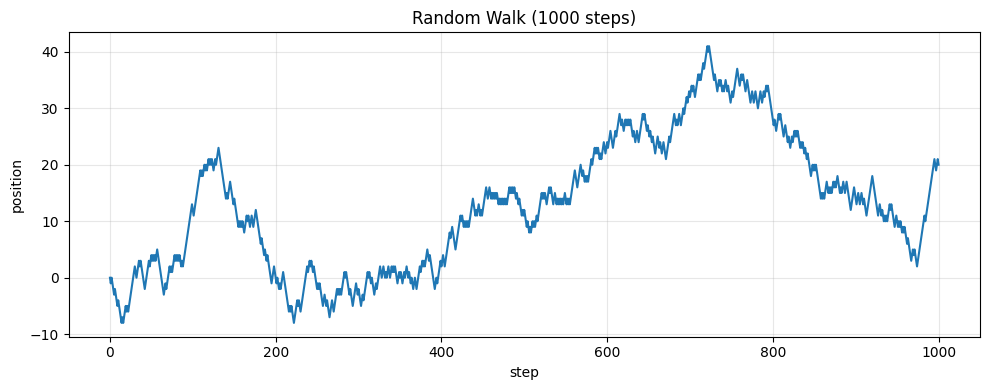

In [7]:
# 用 np.random.choice([-1,1], size=1000) + np.cumsum 生成 1000 步随机游走并画折线图
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)                          # 可复现，想看不同结果可删掉

steps = np.random.choice([-1, 1], size=1000)   # 1000 步，每步 ±1
walk = np.cumsum(steps)                        # 累加 → 随机游走位置

# 想让图从 0 出发，可以把 0 补到最前面
walk = np.concatenate([[0], walk])             # 长度变 1001，walk[0]=0

plt.figure(figsize=(10, 4))
plt.plot(walk)
plt.title('Random Walk (1000 steps)')
plt.xlabel('step')
plt.ylabel('position')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 5. 晚间综合：余弦相似度

In [9]:
# 5 个 8 维随机向量（np.random.randn(5,8)）
# 1) 按公式 cos = a·b / (|a||b|) 算两两相似度矩阵 (5x5)
# 2) 对每个向量，输出与它最相似的另一向量编号
# 3) 验证：全部归一化后直接算点积，结果应相同
# 思考：这就是第 15 周向量数据库检索的本质
import numpy as np

np.random.seed(42)
V = np.random.randn(5, 8)          # 5 个 8 维向量，shape (5,8)

# ---------- 1) 按公式算两两余弦相似度矩阵 ----------
norms = np.linalg.norm(V, axis=1)             # 每个向量的 L2 范数，shape (5,)
dot = V @ V.T                                 # 两两点积矩阵，shape (5,5)
sim1 = dot / np.outer(norms, norms)           # 除以 |a||b|，得到余弦相似度

print('余弦相似度矩阵:\n', np.round(sim1, 4))

# ---------- 2) 每个向量最相似的另一向量 ----------
print('\n最相似邻居:')
for i in range(5):
    row = sim1[i].copy()
    row[i] = -np.inf                          # 排除自己
    j = np.argmax(row)
    print(f'  向量 {i} → 最相似 {j}，相似度 {sim1[i, j]:.4f}')

# ---------- 3) 验证：归一化后点积 ----------
V_norm = V / norms[:, None]                   # 每行归一化成单位向量
sim2 = V_norm @ V_norm.T                      # 单位向量点积 = 余弦相似度

print('\n两种方法一致:', np.allclose(sim1, sim2))
print('归一化后点积矩阵:\n', np.round(sim2, 4))
#余弦相似度 = 点积 / 两个范数之积，V @ V.T 得点积矩阵，np.outer(norms, norms) 得分母，相除即相似度矩阵；找最相似要先把对角线设 -inf 排除自己，再 argmax；归一化后单位向量点积直接等于余弦相似度，验证 allclose 一致。这就是向量数据库检索的本质：编码 → 归一化 → 点积 → 取 top-k，规模大了换 ANN 索引。

余弦相似度矩阵:
 [[ 1.     -0.5813 -0.6409  0.0362 -0.3652]
 [-0.5813  1.      0.3962  0.1566  0.6628]
 [-0.6409  0.3962  1.     -0.3413  0.1211]
 [ 0.0362  0.1566 -0.3413  1.      0.0129]
 [-0.3652  0.6628  0.1211  0.0129  1.    ]]

最相似邻居:
  向量 0 → 最相似 3，相似度 0.0362
  向量 1 → 最相似 4，相似度 0.6628
  向量 2 → 最相似 1，相似度 0.3962
  向量 3 → 最相似 1，相似度 0.1566
  向量 4 → 最相似 1，相似度 0.6628

两种方法一致: True
归一化后点积矩阵:
 [[ 1.     -0.5813 -0.6409  0.0362 -0.3652]
 [-0.5813  1.      0.3962  0.1566  0.6628]
 [-0.6409  0.3962  1.     -0.3413  0.1211]
 [ 0.0362  0.1566 -0.3413  1.      0.0129]
 [-0.3652  0.6628  0.1211  0.0129  1.    ]]


## 6. 练习：直方图验证

样本数: 10000
均值:   -0.0021
标准差: 1.0034


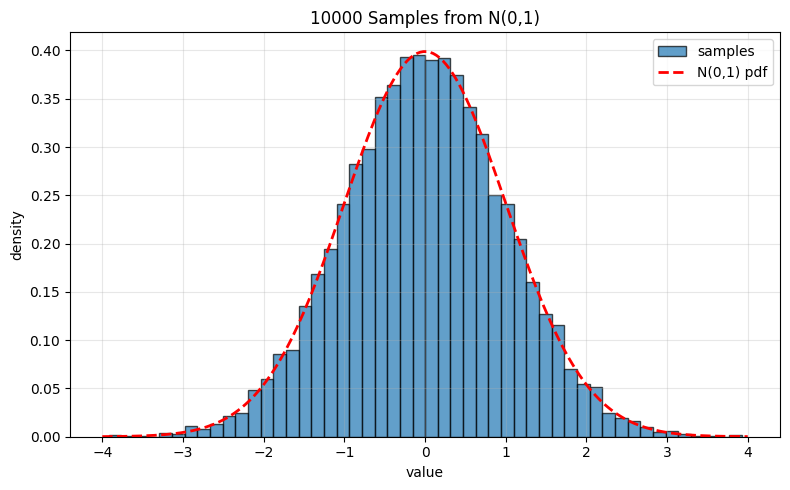

In [10]:
# 生成 10000 个 N(0,1) 样本，画 plt.hist，打印 mean/std 验证接近 0 和 1
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)                    # 可复现
samples = np.random.randn(10000)      # 10000 个 N(0,1) 样本

# 打印统计量
print(f'样本数: {len(samples)}')
print(f'均值:   {samples.mean():.4f}')   # 应接近 0
print(f'标准差: {samples.std():.4f}')    # 应接近 1

# 画直方图
plt.figure(figsize=(8, 5))
plt.hist(samples, bins=50, density=True, alpha=0.7, edgecolor='black', label='samples')

# 叠加理论正态曲线，对比形状
x = np.linspace(-4, 4, 200)
pdf = np.exp(-x**2 / 2) / np.sqrt(2 * np.pi)   # N(0,1) 的概率密度
plt.plot(x, pdf, 'r--', linewidth=2, label='N(0,1) pdf')

plt.title('10000 Samples from N(0,1)')
plt.xlabel('value')
plt.ylabel('density')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()